<a href="https://colab.research.google.com/github/gachet/ad-1-26/blob/main/algo/polynomial_GRADIENTE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

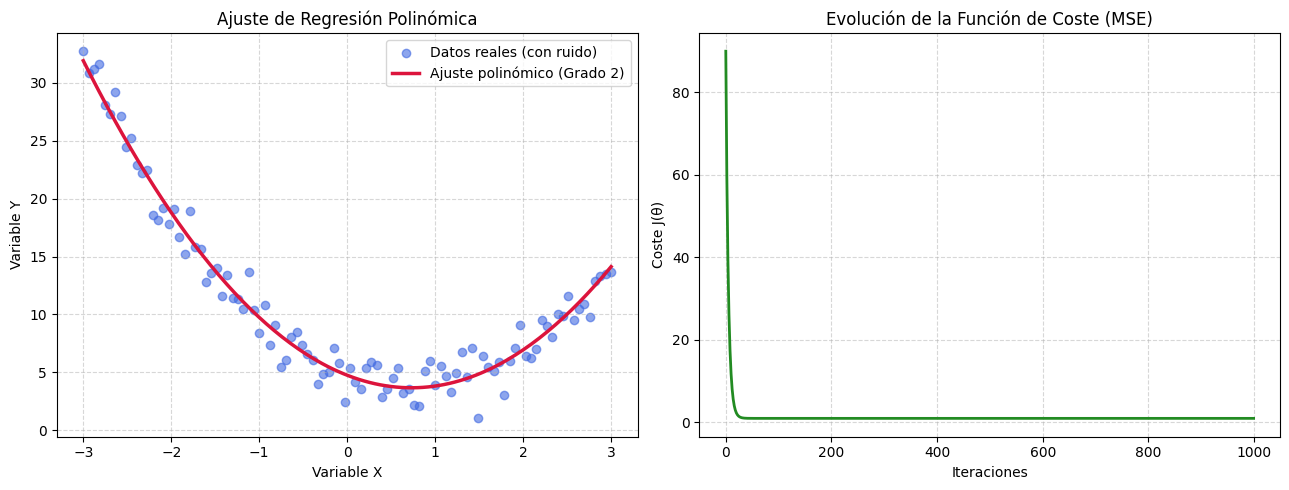

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generar datos de ejemplo (curva cuadrática con algo de ruido)
np.random.seed(42)
X = np.linspace(-3, 3, 100).reshape(-1, 1)
y = 2 * X**2 - 3 * X + 5 + np.random.randn(100, 1) * 1.5

# 2. Función para crear características polinómicas y escalarlas
def preparar_datos(X, grado):
    # Crear matriz de potencias: [x, x^2, ..., x^grado]
    X_poly = np.hstack([X**i for i in range(1, grado + 1)])

    # Estandarizar (Media = 0, Desviación estándar = 1)
    media = np.mean(X_poly, axis=0)
    desv = np.std(X_poly, axis=0)
    X_norm = (X_poly - media) / desv

    # Agregar columna de unos al inicio para el término independiente (theta_0)
    X_final = np.c_[np.ones((X_norm.shape[0], 1)), X_norm]
    return X_final, media, desv

# 3. Algoritmo de Descenso por Gradiente
def descenso_gradiente(X_b, y, lr=0.1, iteraciones=1000):
    N, d = X_b.shape
    theta = np.zeros((d, 1))
    historial_coste = []

    for _ in range(iteraciones):
        predicciones = X_b @ theta
        error = predicciones - y

        # Calcular el coste (MSE)
        coste = (1 / (2 * N)) * np.sum(error ** 2)
        historial_coste.append(coste)

        # Calcular gradientes y actualizar parámetros
        gradientes = (1 / N) * (X_b.T @ error)
        theta = theta - lr * gradientes

    return theta, historial_coste

# --- EJECUCIÓN ---
grado = 2
X_preparada, media, desv = preparar_datos(X, grado)
theta_optimo, costes = descenso_gradiente(X_preparada, y, lr=0.1, iteraciones=1000)

# --- PREDICCIÓN PARA DIBUJAR LA CURVA SUAVE ---
# Generamos puntos ordenados en el eje X para que la línea se vea continua
X_linea = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
X_linea_poly = np.hstack([X_linea**i for i in range(1, grado + 1)])
# Usamos la media y desviación del entrenamiento (muy importante)
X_linea_norm = (X_linea_poly - media) / desv
X_linea_final = np.c_[np.ones((X_linea_norm.shape[0], 1)), X_linea_norm]
y_pred = X_linea_final @ theta_optimo

# --- VISUALIZACIÓN CON MATPLOTLIB ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico 1: Datos reales vs Curva ajustada
ax1.scatter(X, y, color='royalblue', alpha=0.6, label='Datos reales (con ruido)')
ax1.plot(X_linea, y_pred, color='crimson', linewidth=2.5, label=f'Ajuste polinómico (Grado {grado})')
ax1.set_title('Ajuste de Regresión Polinómica')
ax1.set_xlabel('Variable X')
ax1.set_ylabel('Variable Y')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# Gráfico 2: Caída del error (Coste MSE)
ax2.plot(range(len(costes)), costes, color='forestgreen', linewidth=2)
ax2.set_title('Evolución de la Función de Coste (MSE)')
ax2.set_xlabel('Iteraciones')
ax2.set_ylabel('Coste J(θ)')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
